(360, 360, 3)


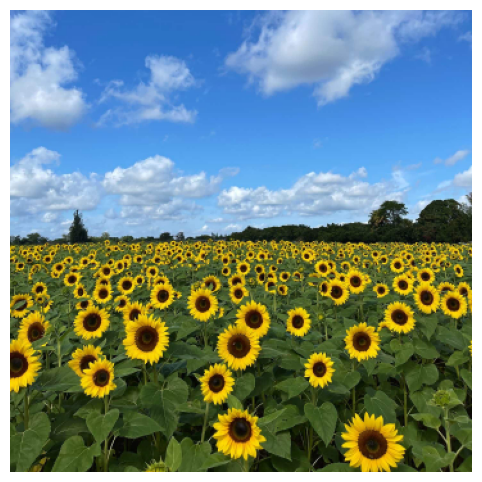

In [11]:
import cv2 as cv, numpy as np, matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

im = cv.imread('../images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, "image not found: check the path and filename in images/"
rgb  = cv.cvtColor(im, cv.COLOR_BGR2RGB)
b, g, r = [c.astype(np.float32) / 255 for c in cv.split(im)]
gray = np.clip((r + g) / 2 - b, 0, None)
print(im.shape)
plt.figure(figsize=(8, 6)); plt.imshow(rgb); plt.axis('off'); plt.show()

In [13]:
sigma_min, k, n_levels = 3.0, 1.2, 14          # geometric progression of scales
sigmas = sigma_min * k ** np.arange(n_levels)
print(f"sigma range: {sigmas[0]:.2f} to {sigmas[-1]:.2f}  (radius {np.sqrt(2)*sigmas[0]:.1f} to {np.sqrt(2)*sigmas[-1]:.1f} px)")

BRIGHT = True        # True: bright blobs on darker background
sign = -1 if BRIGHT else 1

space = np.empty((n_levels,) + gray.shape, np.float32)
for i, s in enumerate(sigmas):
    blurred = cv.GaussianBlur(gray, (0, 0), s)
    space[i] = sign * (s ** 2) * cv.Laplacian(blurred, cv.CV_32F)   # scale-normalised LoG

sigma range: 3.00 to 32.10  (radius 4.2 to 45.4 px)


In [15]:
thr_rel = 0.3                                   # fraction of the strongest response
is_max  = space == maximum_filter(space, size=(3, 3, 3))
strong  = space > thr_rel * space.max()
pts = np.argwhere(is_max & strong)              # rows of (level, y, x)

ysmooth = cv.GaussianBlur(gray, (0, 0), 2)
cands = [(space[l, y, x], x, y, sigmas[l]) for l, y, x in pts if ysmooth[y, x] > 0.15]
cands.sort(reverse=True)                        # strongest first
print(len(cands), "raw extrema")

245 raw extrema


201 circles after pruning


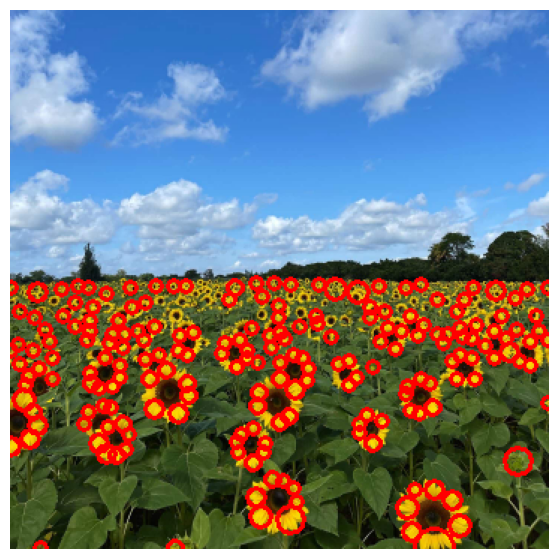

In [16]:
keep = []
for resp, x, y, s in cands:
    r = np.sqrt(2) * s
    # keep only if this centre lies outside every already-kept (stronger) circle
    if all(np.hypot(x - xk, y - yk) > max(r, np.sqrt(2) * sk) for _, xk, yk, sk in keep):
        keep.append((resp, x, y, s))
print(len(keep), "circles after pruning")

out = rgb.copy()
for _, x, y, s in keep:
    cv.circle(out, (int(x), int(y)), int(round(np.sqrt(2) * s)), (255, 0, 0), 2)
plt.figure(figsize=(10, 7)); plt.imshow(out); plt.axis('off'); plt.show()

In [17]:
largest = sorted(keep, key=lambda c: c[3], reverse=True)[:5]
print(f"{'x':>5} {'y':>5} {'sigma':>7} {'radius':>7}")
for _, x, y, s in largest:
    print(f"{x:5d} {y:5d} {s:7.2f} {np.sqrt(2)*s:7.1f}")
print(f"sigma range used: {sigmas[0]:.2f} - {sigmas[-1]:.2f}, factor {k} per level, {n_levels} levels")

    x     y   sigma  radius
  283   359    8.96    12.7
  187   340    6.22     8.8
  339   301    6.22     8.8
  167   338    5.18     7.3
  300   344    5.18     7.3
sigma range used: 3.00 - 32.10, factor 1.2 per level, 14 levels
